# Task 2: PCA and clustering of daily portfolio returns (HW5)

Plan: (a) PCA on the 25 portfolio return series, (b) hierarchical clustering on the PC scores, (c) K-means on the PC scores, (d) test whether the clusters carry information about NBER recessions.

In [10]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from sklearn.decomposition import PCA
from sklearn.cluster import AgglomerativeClustering, KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score, roc_auc_score, roc_curve, confusion_matrix
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import TimeSeriesSplit
from scipy.cluster.hierarchy import linkage, dendrogram, cophenet
from scipy.spatial.distance import pdist

SEED = 37
PALETTE = plt.get_cmap("tab10").colors   # one fixed colour per cluster id, reused in every plot

In [11]:
data = pd.read_csv("HW5Portfolio25.csv")
dates = pd.to_datetime(data["Date"], format="%Y%m%d")
X = data.drop(columns="Date").apply(pd.to_numeric, errors="coerce")

# Return files often encode "missing" as -99.99 / -999. Treat anything <= -99 (%) as missing.
sentinels = int((X <= -99).sum().sum())
print("Sentinel values found:", sentinels, "| NaNs:", int(X.isna().sum().sum()))
X = X.mask(X <= -99)

valid = X.notna().all(axis=1)
X, dates = X.loc[valid], dates.loc[valid]
print("Rows kept:", len(X), "| Portfolios:", X.shape[1], "|", dates.min().date(), "to", dates.max().date())

# Equal-weighted average return: a simple market proxy used later to describe clusters
market = pd.Series(X.mean(axis=1).to_numpy(), index=dates, name="market")

Sentinel values found: 0 | NaNs: 0
Rows kept: 25438 | Portfolios: 25 | 1926-07-01 to 2023-02-28


## (a) PCA
**Standardization:** all 25 series are daily returns in the same units, so I run PCA on the raw data. Standardizing would give each portfolio equal weight regardless of its volatility and discard the useful information about which portfolios drive the variation. 

**Number of components:** I look at the scree plot (where the curve flattens) and the cumulative variance, and keep the smallest number of PCs reaching 90% of variance.

PCs needed for >=90% variance: 6 (cumulative = 0.906)
Variance explained by first 6 PCs: [0.652 0.133 0.053 0.03  0.025 0.014]


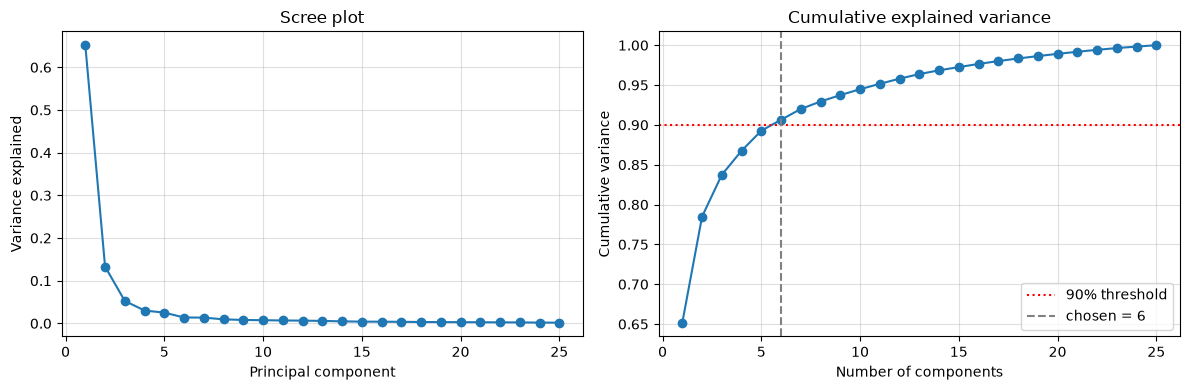

In [12]:
pca_all = PCA().fit(X)
explained = pca_all.explained_variance_ratio_
cumulative = np.cumsum(explained)
n_components = int(np.argmax(cumulative >= 0.90) + 1)
print(f"PCs needed for >=90% variance: {n_components} (cumulative = {cumulative[n_components-1]:.3f})")
print("Variance explained by first 6 PCs:", np.round(explained[:6], 3))

comp = np.arange(1, len(explained) + 1)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(comp, explained, marker="o")
axes[0].set(title="Scree plot", xlabel="Principal component", ylabel="Variance explained")
axes[1].plot(comp, cumulative, marker="o")
axes[1].axhline(0.90, color="red", ls=":", label="90% threshold")
axes[1].axvline(n_components, color="gray", ls="--", label=f"chosen = {n_components}")
axes[1].set(title="Cumulative explained variance", xlabel="Number of components", ylabel="Cumulative variance")
axes[1].legend()
for a in axes: a.grid(alpha=.4)
plt.tight_layout(); plt.show()

,PC1,PC2,PC3,PC4,PC5,PC6
Date,,,,,,
1926-07-01,0.147804,-0.500030,0.740417,0.203009,0.323630,0.928243
1926-07-02,0.640377,0.210350,-0.631616,1.456718,1.295260,-1.536060
1926-07-06,0.488396,0.185949,-0.479472,-0.453191,0.154566,-0.713260
1926-07-07,-0.425375,-0.894778,-1.255452,-0.179676,-0.105771,1.555379
1926-07-08,0.503189,0.265711,-0.925185,0.543001,0.998305,-0.914831


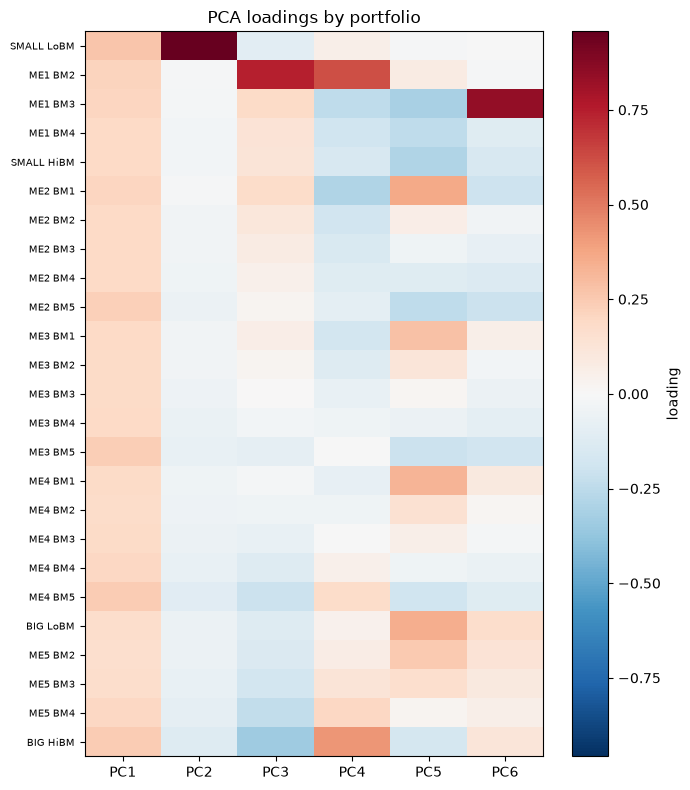

In [13]:
# Represent every day by its scores on the chosen PCs
pca = PCA(n_components=n_components)
scores = pca.fit_transform(X)
pc_cols = [f"PC{i}" for i in range(1, n_components + 1)]
pc_scores = pd.DataFrame(scores, columns=pc_cols, index=dates)
display(pc_scores.head())

# Loadings: how strongly each portfolio contributes to each PC (helps interpret the PCs)
loadings = pd.DataFrame(pca.components_.T, index=X.columns, columns=pc_cols)
fig, ax = plt.subplots(figsize=(7, 8))
im = ax.imshow(loadings, aspect="auto", cmap="RdBu_r", vmin=-loadings.abs().max().max(), vmax=loadings.abs().max().max())
ax.set_xticks(range(n_components)); ax.set_xticklabels(pc_cols)
ax.set_yticks(range(len(loadings))); ax.set_yticklabels(loadings.index, fontsize=7)
ax.set_title("PCA loadings by portfolio"); fig.colorbar(im, label="loading"); plt.tight_layout(); plt.show()

**Interpreting the PCs:** a PC whose loadings all share a sign is a market-wide factor (typically PC1); PCs whose loadings change sign across portfolio groups are spreads such as small-vs-large or value-vs-growth. Describe what the heatmap shows here.

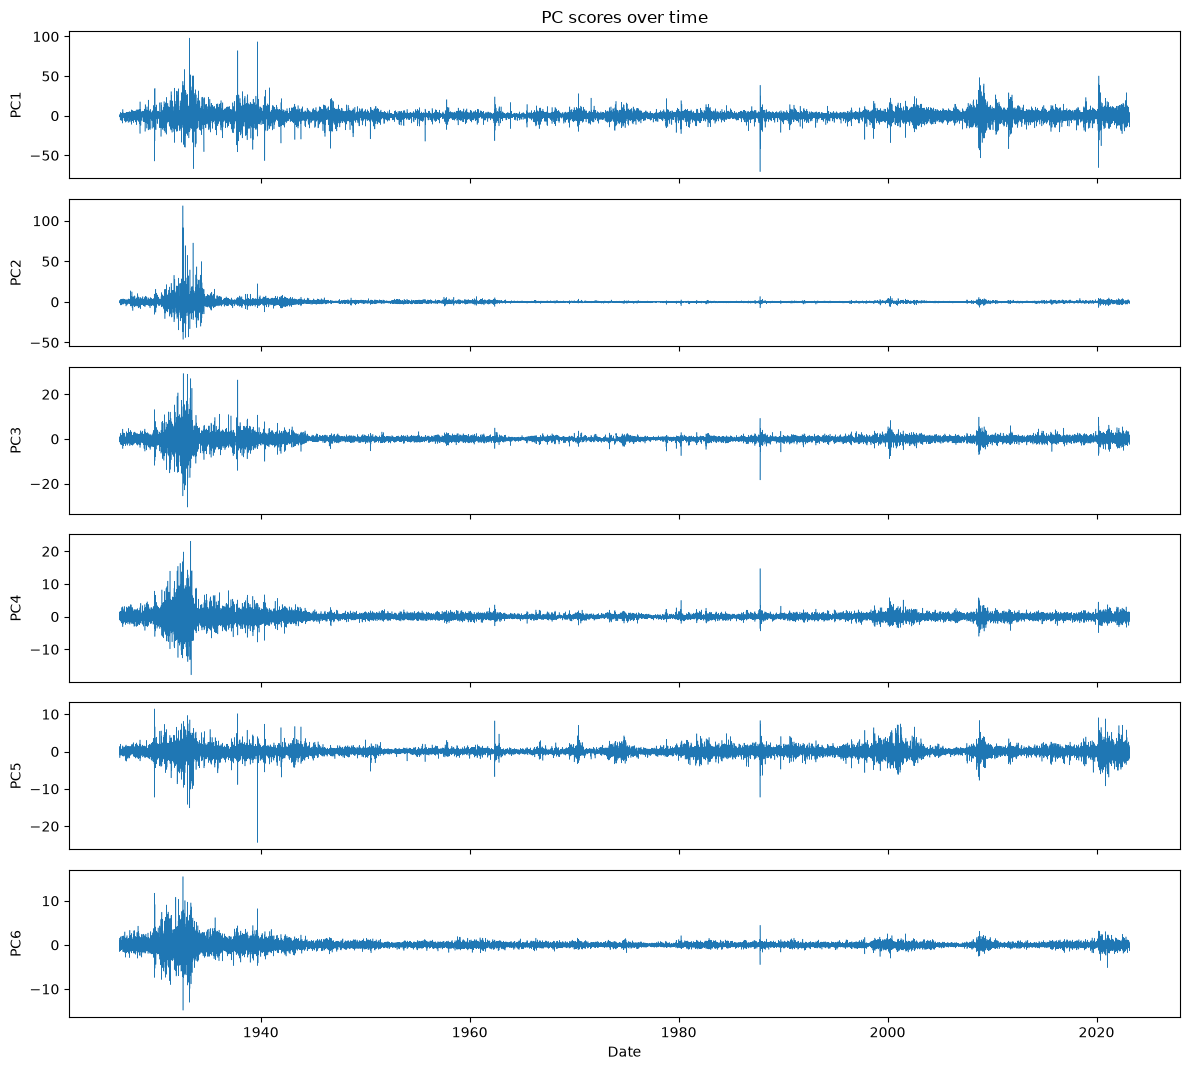

In [14]:
fig, axes = plt.subplots(n_components, 1, figsize=(12, 1.8 * n_components), sharex=True)
axes = np.atleast_1d(axes)
for ax, pc in zip(axes, pc_cols):
    ax.plot(pc_scores.index, pc_scores[pc], lw=0.4); ax.set_ylabel(pc)
axes[0].set_title("PC scores over time"); axes[-1].set_xlabel("Date")
plt.tight_layout(); plt.show()

## Helpers shared by (b), (c) and (d)
Cluster ids are arbitrary, so I relabel them by volatility of the market proxy (0 = calmest day type, highest id = most volatile). This keeps colours and names consistent across methods.

In [15]:
def relabel_by_vol(labels):
    vol = pd.Series(market.to_numpy()).groupby(labels).std().sort_values()
    mapping = {old: new for new, old in enumerate(vol.index)}
    return np.array([mapping[l] for l in labels])

def profile(labels):
    df = pd.DataFrame({"cluster": labels, "market": market.to_numpy()})
    g = df.groupby("cluster")["market"]
    return pd.DataFrame({"days": g.size(), "share": g.size() / len(df),
                         "mean_return": g.mean(), "return_std": g.std()}).round(4)

def scatter_pairs(labels, centers=None, title=""):
    pairs = [(0, 1), (0, 2), (1, 2)] if n_components >= 3 else [(0, 1)]
    fig, axes = plt.subplots(1, len(pairs), figsize=(5.5 * len(pairs), 5))
    axes = np.atleast_1d(axes)
    for ax, (i, j) in zip(axes, pairs):
        for c in np.unique(labels):
            m = labels == c
            ax.scatter(pc_scores.iloc[m, i], pc_scores.iloc[m, j], s=5, alpha=.4, color=PALETTE[c], label=f"Cluster {c}")
        if centers is not None:
            ax.scatter(centers[:, i], centers[:, j], marker="X", s=160, color="black", edgecolor="white", label="Centroids")
        ax.set(xlabel=pc_cols[i], ylabel=pc_cols[j]); ax.grid(alpha=.3)
    axes[0].legend(markerscale=2, fontsize=8); fig.suptitle(title); plt.tight_layout(); plt.show()

def monthly_share(labels, k):
    df = pd.DataFrame({"cluster": labels}, index=dates.to_numpy())
    s = pd.crosstab(df.index.to_period("M"), df["cluster"], normalize="index")
    return s.reindex(columns=range(k), fill_value=0)

def plot_monthly_share(share, title):
    s = share.copy(); s.index = s.index.to_timestamp()
    ax = s.plot.area(figsize=(13, 4), color=[PALETTE[c] for c in s.columns], linewidth=0)
    ax.set(title=title, xlabel="Date", ylabel="Share of trading days", ylim=(0, 1))
    ax.legend(title="Cluster", bbox_to_anchor=(1.02, 1), loc="upper left"); plt.tight_layout(); plt.show()

## (b) Hierarchical clustering on the PC scores
**Settings and why**
* **Features:** the 6 chosen PC scores, so noise in the low-variance PCs is excluded.
* **Distance:** Euclidean (natural for PC scores, which are uncorrelated and in return units).
* **Linkage:** I compare ward, complete and average using the cophenetic correlation (how faithfully the tree preserves the original pairwise distances) on a random sample, since the full data has too many days for a dendrogram or a pairwise-distance matrix.
* **Number of clusters:** chosen by silhouette score on the same sample, then checked against the dendrogram.

Cophenetic correlation by linkage: {'ward': np.float64(0.556), 'complete': np.float64(0.647), 'average': np.float64(0.892)}


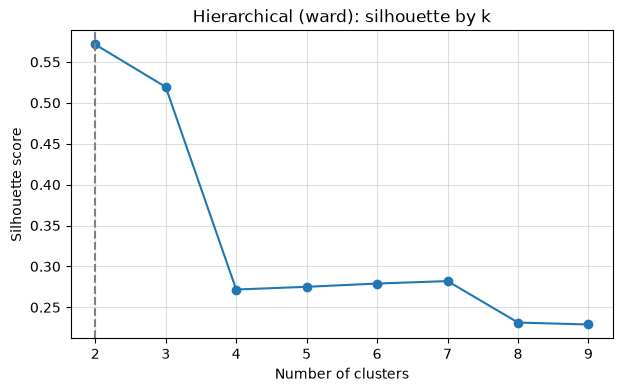

Highest silhouette: k=2


In [16]:
sample = pc_scores.sample(n=min(5000, len(pc_scores)), random_state=SEED)
orig_dist = pdist(sample.to_numpy())

coph = {}
for method in ["ward", "complete", "average"]:
    coph[method] = cophenet(linkage(sample.to_numpy(), method=method), orig_dist)[0]
print("Cophenetic correlation by linkage:", {k: round(v, 3) for k, v in coph.items()})

k_vals = list(range(2, 10))
sil_h = [silhouette_score(sample, AgglomerativeClustering(n_clusters=k, linkage="ward").fit_predict(sample))
         for k in k_vals]
best_k_h = k_vals[int(np.argmax(sil_h))]

plt.figure(figsize=(7, 4)); plt.plot(k_vals, sil_h, marker="o")
plt.axvline(best_k_h, color="gray", ls="--"); plt.grid(alpha=.4)
plt.xlabel("Number of clusters"); plt.ylabel("Silhouette score"); plt.title("Hierarchical (ward): silhouette by k")
plt.show()
print(f"Highest silhouette: k={best_k_h}")

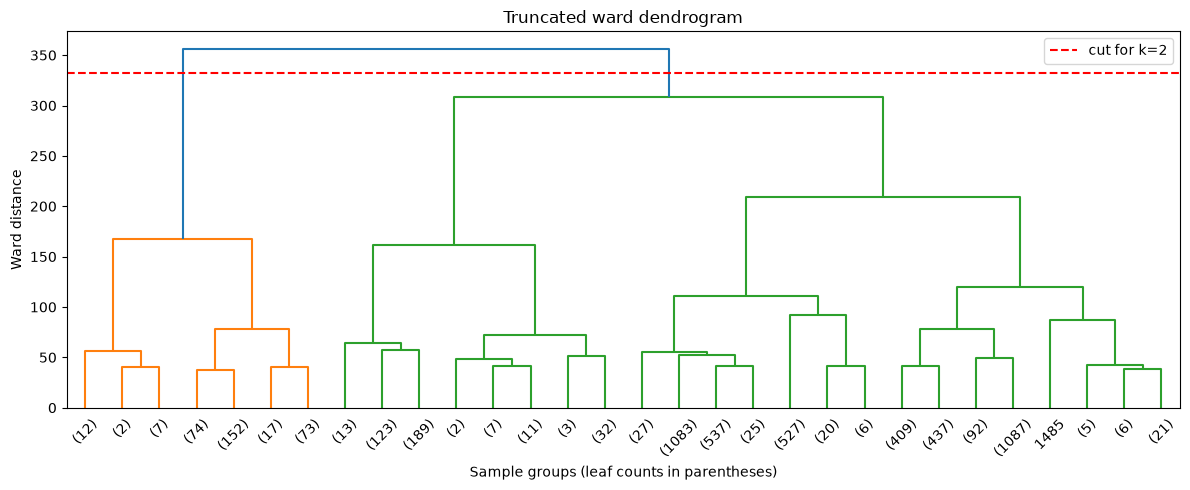

In [17]:
Z = linkage(sample.to_numpy(), method="ward")
# Cutting the tree into k clusters = cutting just below the (k-1) largest merges
cut = (Z[-(best_k_h - 1), 2] + Z[-best_k_h, 2]) / 2

plt.figure(figsize=(12, 5))
dendrogram(Z, truncate_mode="lastp", p=30, color_threshold=cut)
plt.axhline(cut, color="red", ls="--", label=f"cut for k={best_k_h}")
plt.xlabel("Sample groups (leaf counts in parentheses)"); plt.ylabel("Ward distance")
plt.title("Truncated ward dendrogram"); plt.legend(); plt.tight_layout(); plt.show()

,days,share,mean_return,return_std
cluster,,,,
0,23188,0.9115,0.2678,0.8938
1,2250,0.0885,-2.1915,1.3165


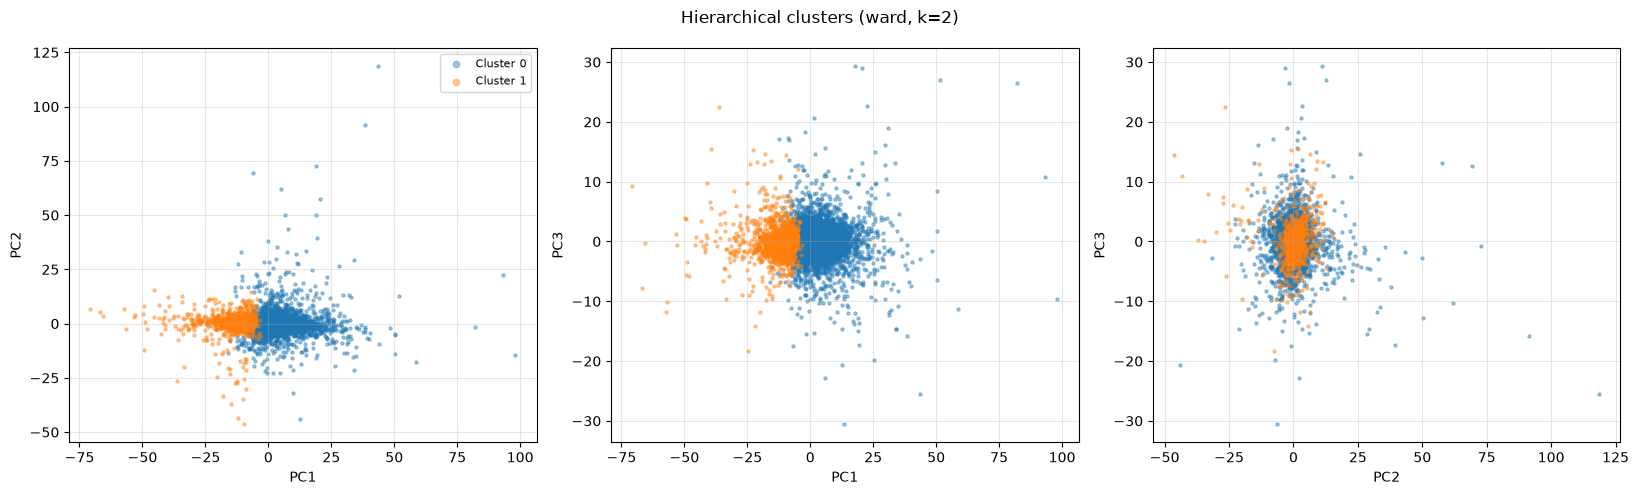

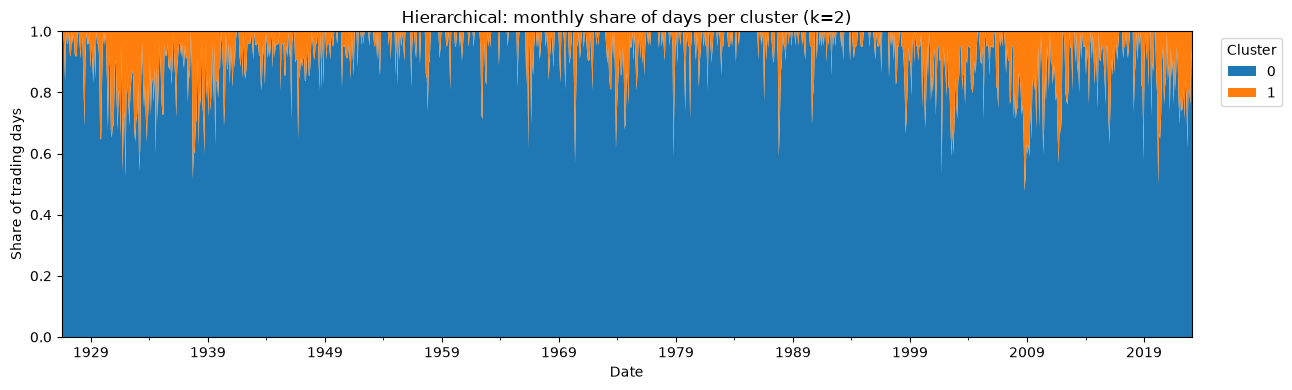

In [18]:
# Fit on every day (ward on ~26k rows is memory-heavy but feasible; if it fails, fit on `sample` and
# assign the remaining days to the nearest cluster centroid)
hier_labels = relabel_by_vol(AgglomerativeClustering(n_clusters=best_k_h, linkage="ward").fit_predict(pc_scores))

display(profile(hier_labels))
scatter_pairs(hier_labels, title=f"Hierarchical clusters (ward, k={best_k_h})")
plot_monthly_share(monthly_share(hier_labels, best_k_h), f"Hierarchical: monthly share of days per cluster (k={best_k_h})")

**Discussion (b):** describe the cluster profile table above (e.g. whether the highest-id cluster has a much larger return std, meaning clusters separate calm from turbulent days), and note whether k chosen by silhouette agrees with the largest gap in the dendrogram.

## (c) K-means on the PC scores
**Settings and why**
* **Features:** same 6 PC scores. K-means minimises within-cluster squared Euclidean distance, which fits uncorrelated PC scores.
* **Initialization:** `n_init=20` random restarts and keep the best, because K-means can land in poor local optima.
* **k:** elbow plot (inertia) and silhouette score on the sample. Silhouette picks the final k, with the elbow as a sanity check.

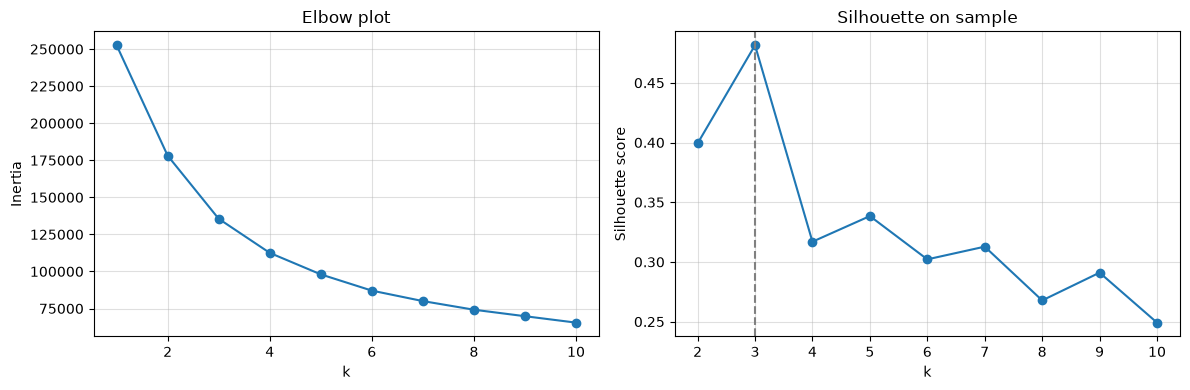

Highest silhouette: k=3


In [19]:
inertias, sil_k = [], []
for k in range(1, 11):
    km = KMeans(n_clusters=k, n_init=20, random_state=SEED).fit(sample)
    inertias.append(km.inertia_)
    if k >= 2: sil_k.append(silhouette_score(sample, km.labels_))
k_range = list(range(2, 11))
best_k_km = k_range[int(np.argmax(sil_k))]

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(range(1, 11), inertias, marker="o"); axes[0].set(title="Elbow plot", xlabel="k", ylabel="Inertia")
axes[1].plot(k_range, sil_k, marker="o"); axes[1].axvline(best_k_km, color="gray", ls="--")
axes[1].set(title="Silhouette on sample", xlabel="k", ylabel="Silhouette score")
for a in axes: a.grid(alpha=.4)
plt.tight_layout(); plt.show()
print(f"Highest silhouette: k={best_k_km}")

In [ ]:
kmeans = KMeans(n_clusters=best_k_km, n_init=20, random_state=SEED).fit(pc_scores)
km_labels = relabel_by_vol(kmeans.labels_)

# Centroids need the same relabelling so colours match
order = pd.Series(market.to_numpy()).groupby(kmeans.labels_).std().sort_values().index
centers = kmeans.cluster_centers_[list(order)]

display(profile(km_labels))
scatter_pairs(km_labels, centers=centers, title=f"K-means clusters (k={best_k_km}), projected onto PC pairs")
plot_monthly_share(monthly_share(km_labels, best_k_km), f"K-means: monthly share of days per cluster (k={best_k_km})")

print("Agreement between hierarchical and K-means labels (adjusted Rand index):",
      round(adjusted_rand_score(hier_labels, km_labels), 3))

**Discussion (c):** describe the profile table and scatter plots (centroids are shown in the 2-D projections only; the clusters live in 6-D, so overlap in a 2-D view doesn't mean they overlap overall). Comment on the adjusted Rand index: 1 means the two methods agree exactly, 0 means chance-level agreement.

## (d) Can the clusters predict the NBER recession index?
**Conceptual issue:** clustering is unsupervised. It never sees USREC, so cluster labels have no built-in link to recessions. They *can* still be used as features if the day-type mix in a month differs between recession and expansion months. I test that directly, using K-means shares (the same would work for hierarchical):

1. Compare the average cluster mix in recession vs. non-recession months.
2. Check timing with a lead/lag correlation: do clusters move *before* recessions or only alongside them?
3. Fit a simple classifier on monthly cluster shares with a chronological train/test split (no shuffling, to avoid using the future to predict the past) and report AUC against the 0.5 baseline.

In [ ]:
usrec = pd.read_csv("HW5USREC.csv", parse_dates=["observation_date"])
rec = usrec.assign(month=usrec["observation_date"].dt.to_period("M")).set_index("month")["USREC"]

shares = monthly_share(km_labels, best_k_km)
missing = shares.index.difference(rec.index)
if len(missing): raise ValueError(f"USREC is missing {len(missing)} portfolio months")
y_m = rec.reindex(shares.index).astype(int)
print(f"{len(y_m)} months | {y_m.mean():.1%} are NBER recession months (the no-skill baseline)")

# 1. Average cluster mix: recession vs. expansion months
display(shares.groupby(y_m).mean().rename(index={0: "Expansion", 1: "Recession"}).round(3))

In [ ]:
# 2. Timing: correlation between the high-volatility cluster share and USREC at different lags.
#    Positive lag = share from `lag` months EARLIER vs. today's recession flag (a leading signal).
high = shares[best_k_km - 1]
lags = list(range(-12, 13))
xc = [y_m.corr(high.shift(l)) for l in lags]
plt.figure(figsize=(9, 3.5))
plt.bar(lags, xc, color=["#4C78A8" if l > 0 else "#999999" for l in lags])
plt.axvline(0, color="k", lw=.8)
plt.xlabel("Lag in months (positive = cluster share leads the recession flag)")
plt.ylabel("Correlation"); plt.title("High-volatility cluster share vs. USREC"); plt.grid(alpha=.3); plt.show()
print("Correlation at lag 0:", round(xc[lags.index(0)], 3), "| best lead (lag>0):",
      lags[int(np.argmax(xc[13:])) + 13], "->", round(max(xc[13:]), 3))

In [ ]:
# 3. Classifier on cluster shares. Shares sum to 1, so drop one column to avoid perfect collinearity.
F = shares.iloc[:, 1:]
split = int(len(F) * 0.7)
Xtr, Xte, ytr, yte = F.iloc[:split], F.iloc[split:], y_m.iloc[:split], y_m.iloc[split:]
clf = LogisticRegression(class_weight="balanced", max_iter=1000).fit(Xtr, ytr)
p = clf.predict_proba(Xte)[:, 1]
print(f"Train: {Xtr.index[0]}..{Xtr.index[-1]} | Test: {Xte.index[0]}..{Xte.index[-1]} "
      f"(test recession rate {yte.mean():.1%})")
print(f"Chronological hold-out AUC: {roc_auc_score(yte, p):.3f}")
print("Confusion matrix at 0.5 (rows = actual, cols = predicted):\n", confusion_matrix(yte, p > 0.5))

# Expanding-window check across several time periods
aucs = []
for tr, te in TimeSeriesSplit(n_splits=5).split(F):
    if y_m.iloc[te].nunique() == 2:
        m = LogisticRegression(class_weight="balanced", max_iter=1000).fit(F.iloc[tr], y_m.iloc[tr])
        aucs.append(roc_auc_score(y_m.iloc[te], m.predict_proba(F.iloc[te])[:, 1]))
print("Expanding-window AUCs:", np.round(aucs, 3))

fpr, tpr, _ = roc_curve(yte, p)
plt.figure(figsize=(5, 5)); plt.plot(fpr, tpr, label="Cluster-share logistic model"); plt.plot([0, 1], [0, 1], "k--", label="Chance")
plt.xlabel("False positive rate"); plt.ylabel("True positive rate"); plt.title("Recession prediction from clusters (test period)")
plt.legend(); plt.grid(alpha=.3); plt.show()

In [ ]:
# Visual: cluster composition with NBER recessions shaded
is_rec = y_m.eq(1)
starts = is_rec & ~is_rec.shift(1, fill_value=False)
ends = is_rec & ~is_rec.shift(-1, fill_value=False)

s = shares.copy(); s.index = s.index.to_timestamp()
fig, ax = plt.subplots(figsize=(14, 4.5))
s.plot.area(ax=ax, color=[PALETTE[c] for c in s.columns], linewidth=0)
for a, b in zip(y_m.index[starts], y_m.index[ends]):
    ax.axvspan(a.to_timestamp(), (b + 1).to_timestamp(), color="black", alpha=0.25, zorder=10)
handles, labels = ax.get_legend_handles_labels()
handles.append(Patch(facecolor="black", alpha=0.25)); labels.append("NBER recession")
ax.legend(handles, labels, title="Cluster", bbox_to_anchor=(1.02, 1), loc="upper left")
ax.set(title="K-means day-type mix with NBER recessions shaded", xlabel="Date", ylabel="Share of trading days", ylim=(0, 1))
plt.tight_layout(); plt.show()

### Answer to (d)
*Edit this after running the cells above, citing your own numbers.*

**Short answer:** the clusters cannot predict recessions on their own, but they may carry partial information.
* **Why not on their own:** clustering is unsupervised and groups days by return behaviour (mostly volatility), not by the economic cycle. USREC is also determined retroactively by the NBER, so it is not a daily market outcome.
* **What the evidence shows:** compare the recession vs. expansion cluster mix table, the lead/lag plot (is the relationship contemporaneous or leading?), and the hold-out AUC relative to 0.5, along with the recession base rate. Note that high-volatility episodes also occur outside recessions, which limits precision (see the confusion matrix).
* **Caveats:** only about a dozen distinct recessions, so test-period AUC is noisy; results depend on the chosen k and split date.